In [1]:
!pip install ultralytics


[notice] A new release of pip is available: 25.0.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
!pip install roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 6.6 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 70.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 2.7 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2


In [3]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO
from IPython.display import Image
from roboflow import Roboflow
from kaggle_secrets import UserSecretsClient

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [4]:
user_secrets = UserSecretsClient()
secret_value_0 = user_secrets.get_secret("ROBOFLOW_API_KEY")
rf = Roboflow(api_key=secret_value_0)
project = rf.workspace("license-plate-0yx2x").project("persian-license-plate-for-ocr")
version = project.version(9)
dataset = version.download("yolov11")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to persian-license-plate-for-OCR-9 in yolov11:: 100%|██████████| 998/998 [00:00<00:00, 11724.99it/s]


In [5]:
model = YOLO("yolo11l.pt")

In [6]:
data_yaml = "/kaggle/working/persian-license-plate-for-OCR-9/data.yaml"

In [7]:
result = model.train(data=data_yaml,
                     imgsz=320, 
                     epochs=300, patience=50,
                     batch=4,
                     fliplr=0.0,   
                     device=0,
                     project="runs_plate")

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/persian-license-plate-for-OCR-9/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=300, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


      2/300      1.19G     0.6592      1.153     0.8333         45        320: 100% ━━━━━━━━━━━━ 48/48 9.2it/s 5.2s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 16.4it/s 0.2s.4s
                   all         26        164      0.841      0.347      0.357      0.308

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/300      1.19G     0.6455     0.8563     0.8193         42        320: 100% ━━━━━━━━━━━━ 48/48 9.1it/s 5.3s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 15.1it/s 0.3s.5s
                   all         26        164      0.714      0.429      0.494      0.421

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      4/300      1.21G     0.6504     0.7689     0.8135         51        320: 100% ━━━━━━━━━━━━ 48/48 9.0it/s 5.4s0.1s
                 Class     Images  Instances  

In [22]:
results_dict = result.results_dict
print(results_dict)

{'metrics/precision(B)': 0.5292298452341051, 'metrics/recall(B)': 0.6015325670498084, 'metrics/mAP50(B)': 0.6325977011494253, 'metrics/mAP50-95(B)': 0.557076599516547, 'fitness': 0.557076599516547}


In [23]:
result_path = "/kaggle/working/runs/detect/runs_plate/train"

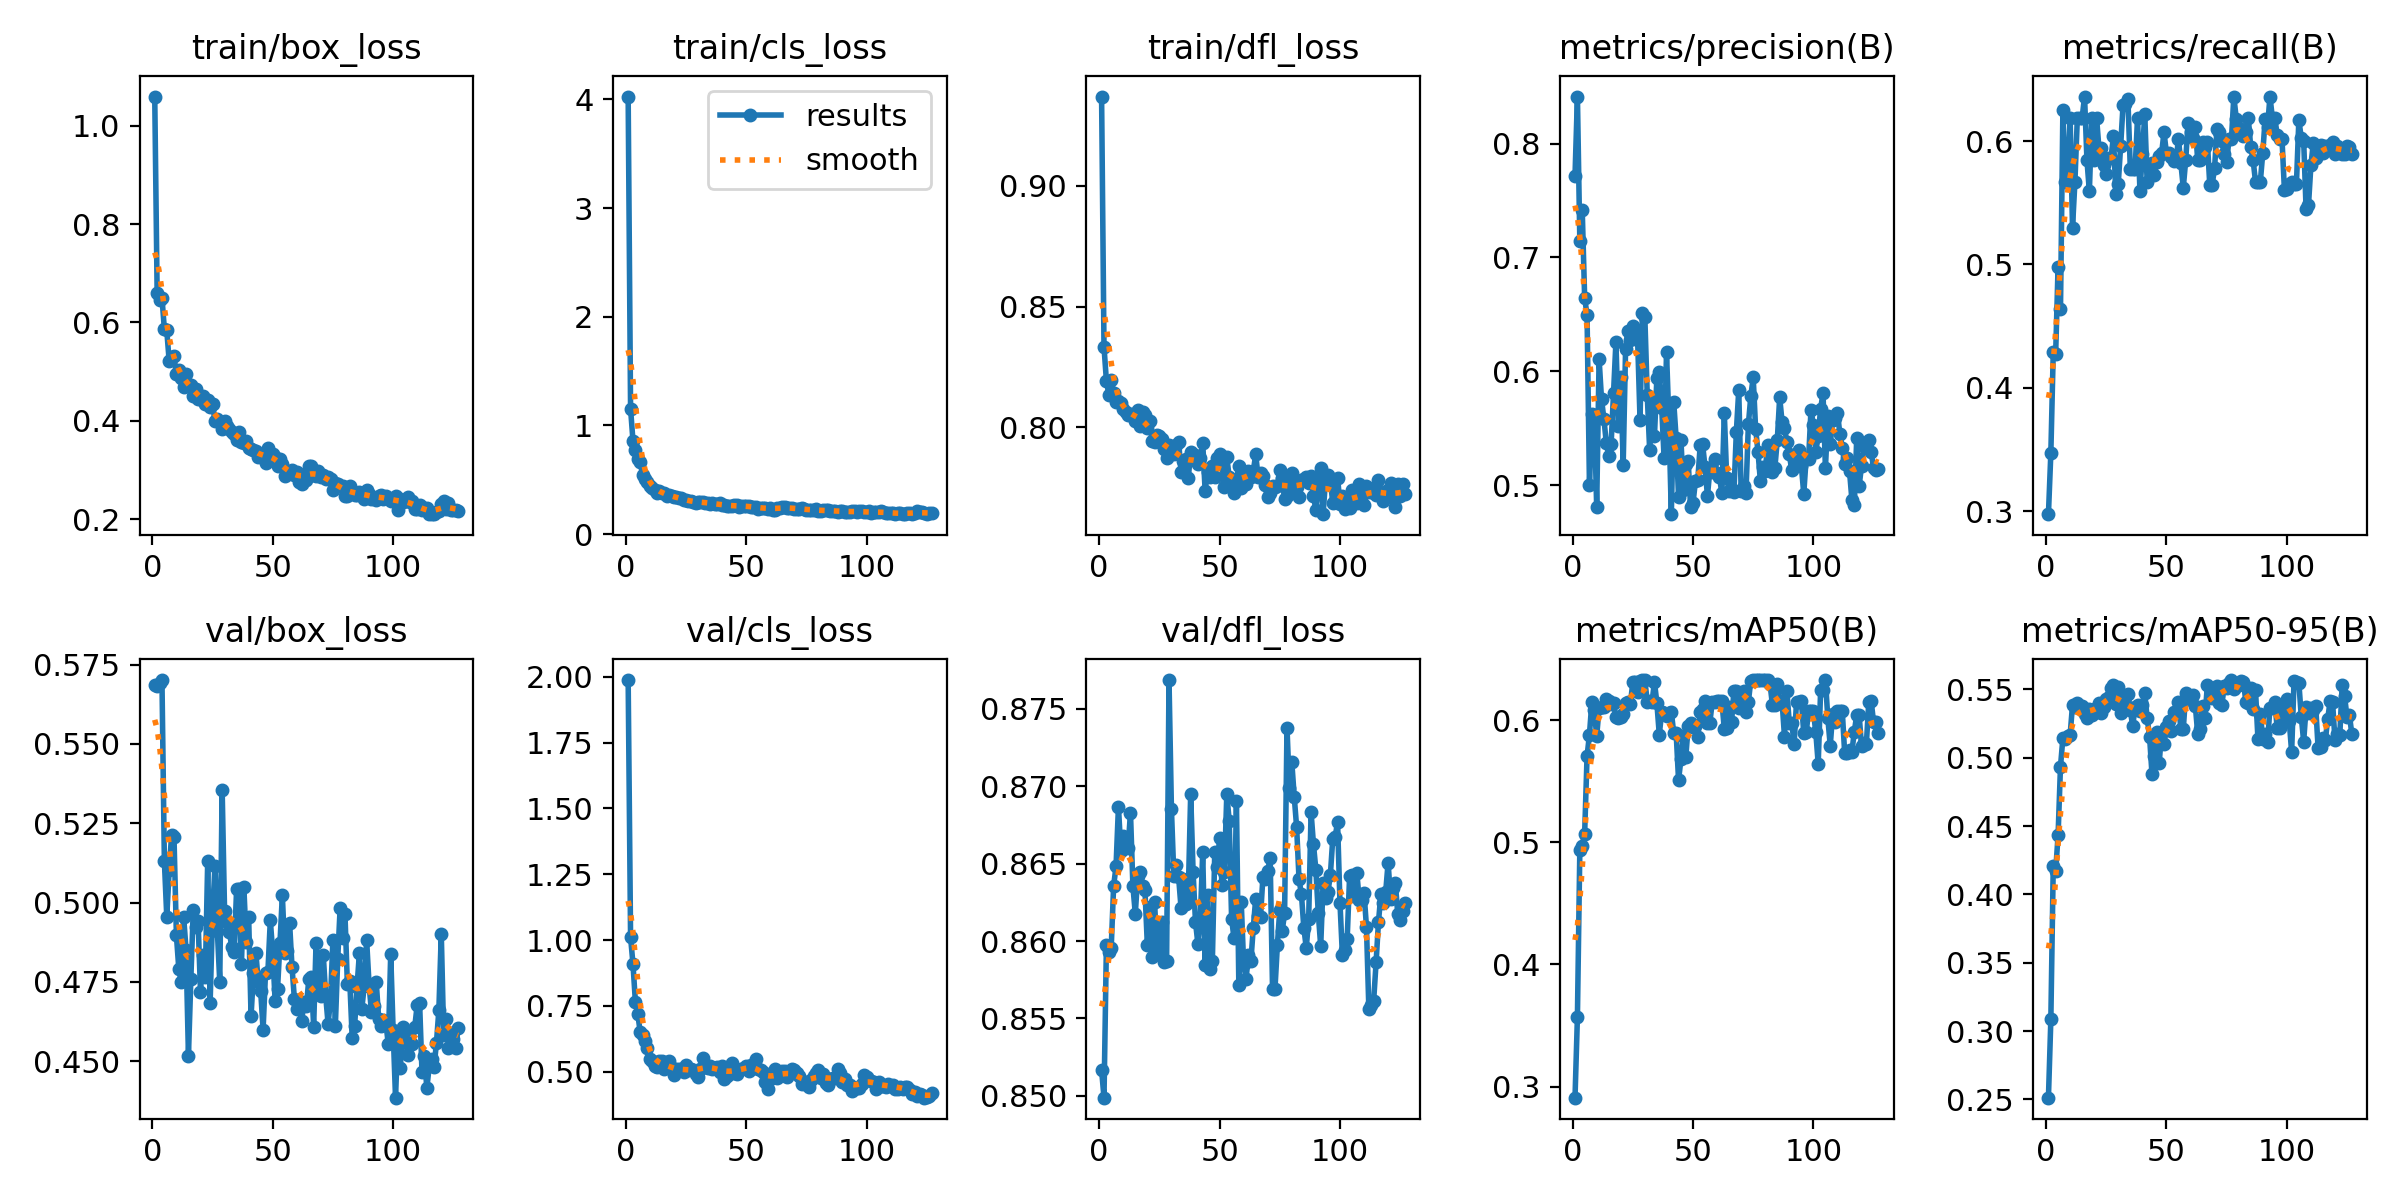

In [24]:
display(Image(f"{result_path}/results.png", width=800, height=800))

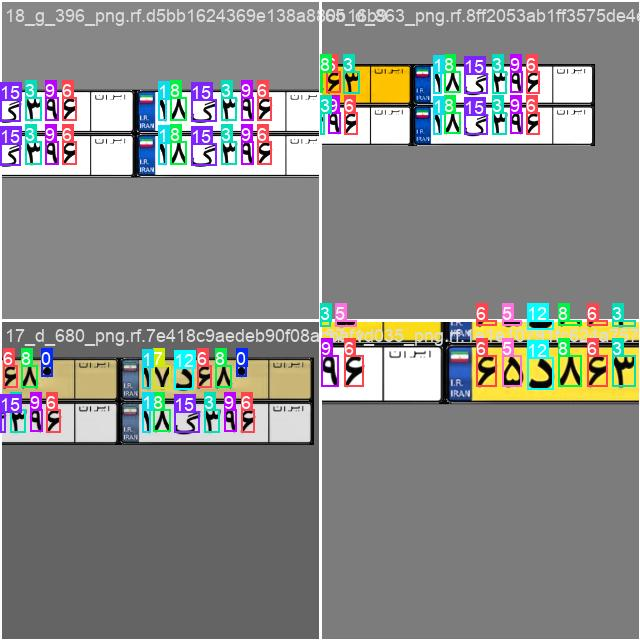

In [11]:
# let's look at the dataset
display(Image(f"{result_path}/train_batch0.jpg", width=600, height=600))

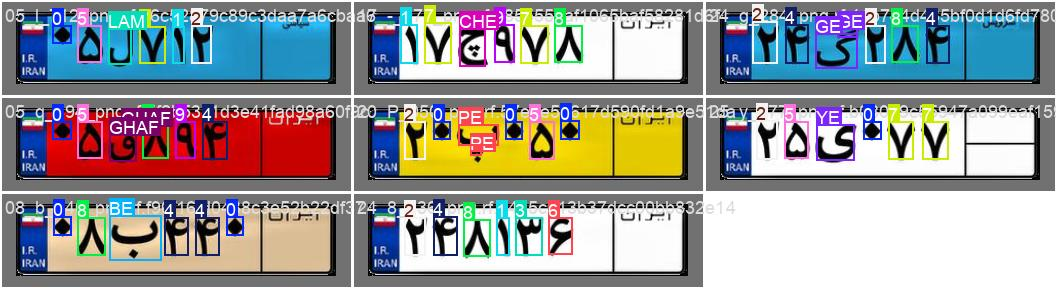

In [12]:
# let's look at the dataset
display(Image(f"{result_path}/val_batch0_labels.jpg", width=4000, height=4000))

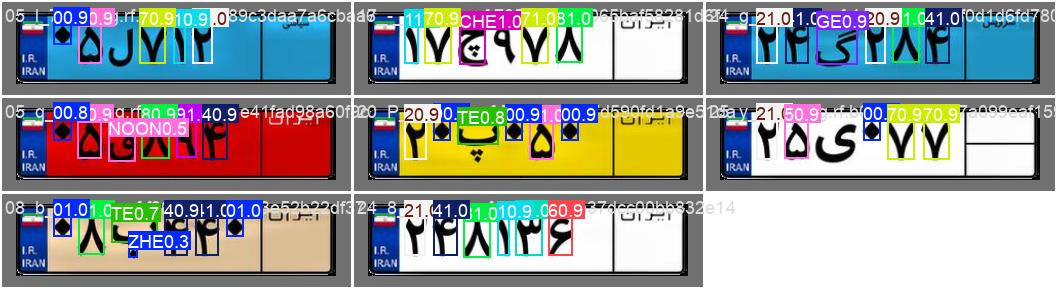

In [13]:
# let's look at the dataset
display(Image(f"{result_path}/val_batch0_pred.jpg", width=5000, height=4000))

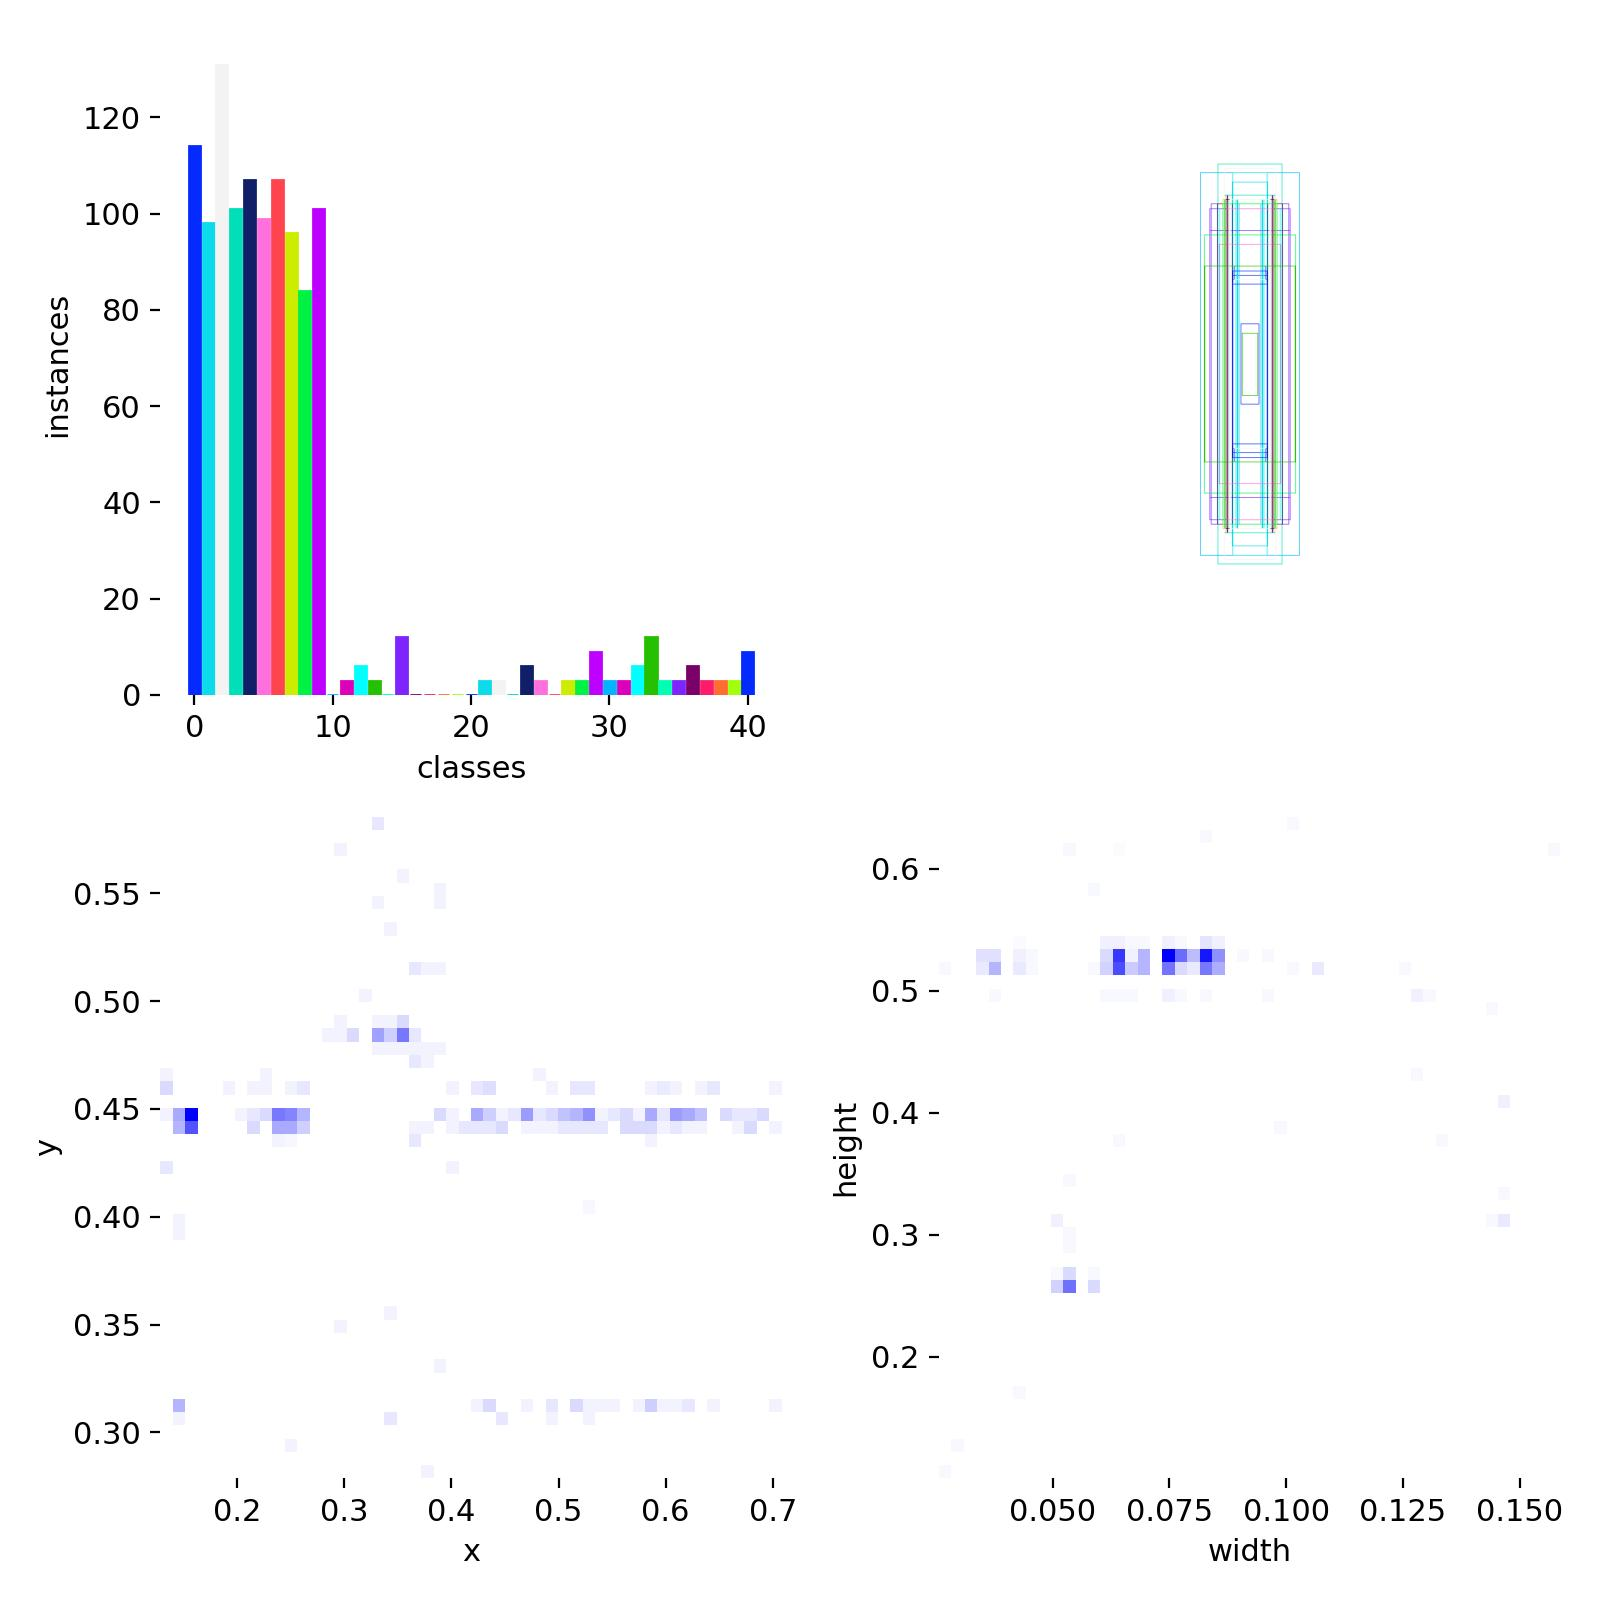

In [14]:
display(Image(f"{result_path}/labels.jpg", width=600, height=600))

## The model is not working well. Probebly because the dataset is small.

In [25]:
def resize_frame(frame,max_width, width, height):
    """
    :param height:
    :param width:
    :param max_width:
    :param frame:
    :return: a resized frame for faster processing
    """
    scale = max_width / width  # e.g. 640/1920 = 0.333
    new_w = max_width
    new_h = int(height * scale)
    frame = cv2.resize(frame, (new_w, new_h))
    return frame

In [27]:
best_weights_path = "/kaggle/working/runs/detect/runs_plate/train/weights/best.pt"

In [28]:
# saving the best weights
best_model = YOLO(best_weights_path)

In [29]:
test_images_path = "/kaggle/input/datasets/sadafpj/my-test-cropped-license-plates"


image 1/1 /kaggle/input/datasets/sadafpj/my-test-cropped-license-plates/truck1.jpg: 64x320 1 2, 2 3s, 1 5, 2 8s, 2 9s, 1 TA, 1 ZA, 20.5ms
Speed: 0.8ms preprocess, 20.5ms inference, 1.4ms postprocess per image at shape (1, 3, 64, 320)


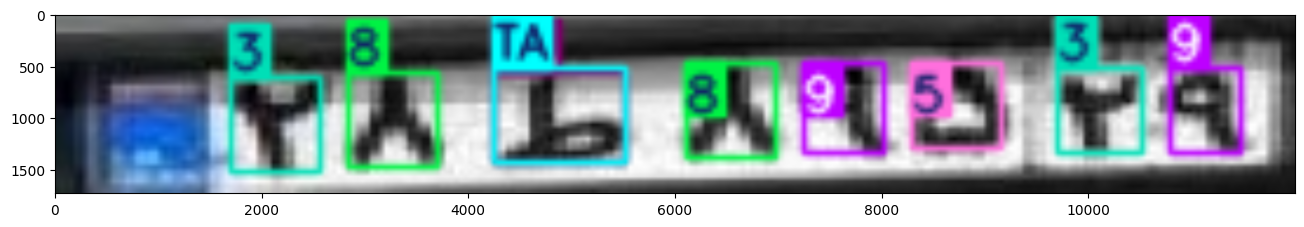

In [70]:
test_results1 = best_model.predict(f"{test_images_path}/truck1.jpg")[0]

plot = test_results1.plot(line_width=1,font_size=2,labels=True,conf=False)

height, width = plot.shape[:2]
plot = resize_frame(plot,12000, width, height)

plt.figure(figsize=(16, 8))
plt.imshow(plot[:, :, ::-1])